In [51]:
import os
import hashlib
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
import tensorflow as tf
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

## **Animal Images Classifier**

### Q1 Inspection Of The Dataset Show The Count Of Each Image Class In The Folder Or Data, Show The Class balance In Visual Form, Also Check Any Duplicate Presense In The Dataset.

In [21]:
# Inspection
dataset_directory = Path(r"C:\Users\namya\Documents\Red and White\Deep Learning\PR - 3\main_data")

# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Find class folders
class_folders = sorted(folder for folder in dataset_directory.iterdir() if folder.is_dir())
print("Number of classes:", len(class_folders))
print("Classes:", [folder.name for folder in class_folders])

Number of classes: 6
Classes: ['Bear', 'Elephant', 'Horse', 'Lion', 'Panda', 'Tiger']


- We Have Used Pathlib To Locate And Organize Image Files And To Navigate Through Dataset Folders And Images Files.
- Then We Speicified Image Extensions For Later Use, And Used iterdir() to fetch Or Store The File Path Of Class folers Like Shown above Each Have Different folder of their name.

In [22]:
# Collection Image Information For Exploratory Data Analysis
records = []

for sub_folder in class_folders:
    for image_path in sub_folder.rglob("*"):
        if image_path.suffix.lower() not in image_extensions:
            continue

        record = {
            "image_path": str(image_path),
            "class": sub_folder.name,
            "width": None,
            "height": None,
            "status": "OK"}

        try:
            with Image.open(image_path) as img:
                record["width"] = img.width
                record["height"] = img.height
                img.verify()
        except Exception:
            record["status"] = "Corrupted"

        records.append(record)
df = pd.DataFrame(records)

- We Have Collected Image Information For EDA. By Fetching All the Sub_folder(animal,lion...) Image path with the help of rglob() and Then Checking The Extension If It is an image and if it is not don't add.
- Storing the Image Details in an dictionary and then opening the image for height and width to be stored and lastly verifying the files if they are corruputed or not and converting then into an DataFrame

In [23]:
# Showing An Quick Analysis Or Overview Of The Dataset
total_images = len(df)
print("\nTotal images:", len(df))
print("\nImages by class:")
print(df["class"].value_counts().sort_index())


Total images: 1507

Images by class:
class
Bear        174
Elephant    238
Horse       283
Lion        280
Panda       241
Tiger       291
Name: count, dtype: int64


- Total Images Are 1507 and Images By Class Are Around 250 To 300 Images And One Class Has Less Images Around 180.

In [24]:
print("\nImage status:")
print(df["status"].value_counts())


Image status:
status
OK    1507
Name: count, dtype: int64


- There Are No Files Which Are Corrupted.

In [25]:
print("\nImage dimensions:")
print(df[["width", "height"]].describe())


Image dimensions:
             width       height
count  1507.000000  1507.000000
mean    462.255474   393.102853
std     256.896989   241.876566
min     148.000000   148.000000
25%     224.000000   224.000000
50%     430.000000   332.000000
75%     713.000000   497.000000
max    1280.000000  1519.000000


- Showing The Height And Width Summary Of This Images. 

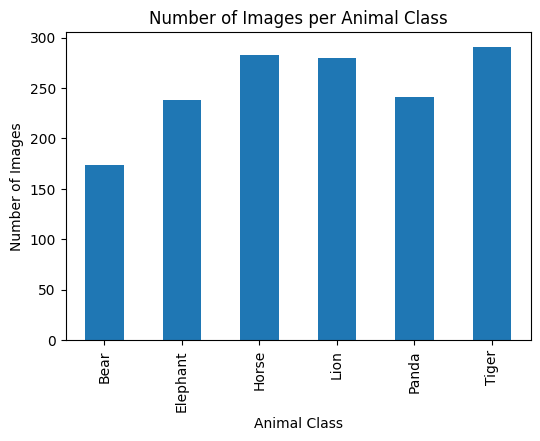

In [26]:
# Showing The Class Balance In Visual form
# Count images in each class
class_counts = df["class"].value_counts().sort_index()

# Visualize class distribution
class_counts.plot(kind="bar", figsize=(6,4))
plt.title("Number of Images per Animal Class")
plt.xlabel("Animal Class")
plt.ylabel("Number of Images")
plt.show()

- From The Above Graph We Can See That Bear Class Has The Lowest The Image Compared To Tiger Which has Highest Images.
- But we Can say That the dataset is moderately Imbalanced Not severely Imbalanced and there is no need for it right now but later is needed we will implement it.

In [27]:
# Checking Any Duplicate Presence In The Dataset
hashes = []

for record in records:
    if record["status"] == "OK":
        image_path = Path(record["image_path"])
        file_hash = hashlib.md5(image_path.read_bytes()).hexdigest()
        hashes.append(file_hash)

print("Total valid images:", len(hashes))
print("Unique images:", len(set(hashes)))
print("Duplicate files:", len(hashes) - len(set(hashes)))

Total valid images: 1507
Unique images: 1409
Duplicate files: 98


- From The Above Code We Can see that we have used hashlib To read the Images fils's content and "hashlib.md5()" To Generate And fingerprint for Uniqueness and "set" To Distance dupilcate images.

- we Have Total 98 Duplicate Images In the dataset. 

### Q2 Show Sample Images Of The Dataset and Check The Image Dimension Are They Consistent Or Not.

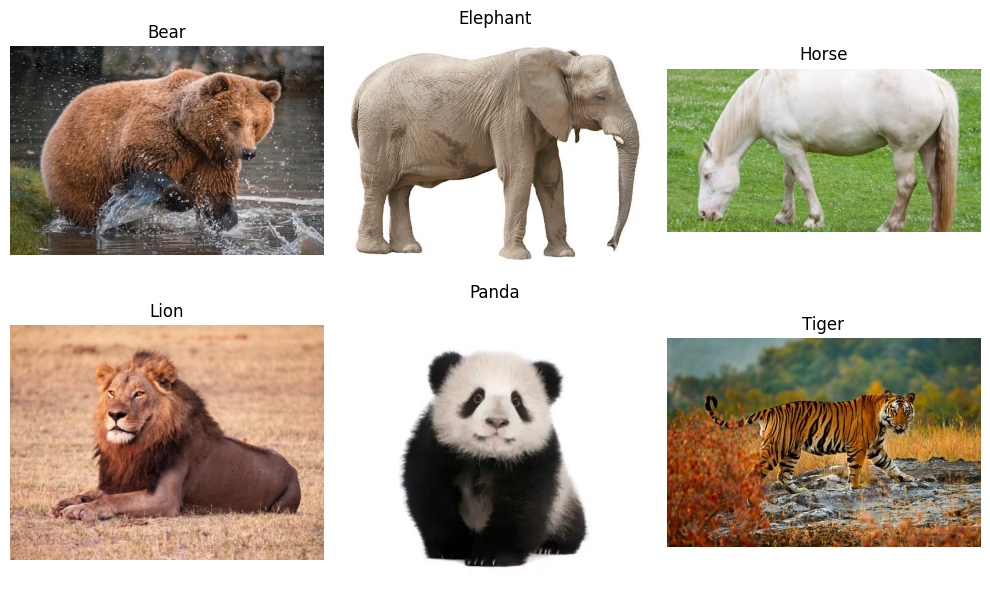

In [28]:
# Showing The Sample Images Of The Dataset
fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for ax, sub_folder in zip(axes.flat, class_folders):
    image_paths = [p for p in sub_folder.rglob("*") if p.is_file() and p.suffix.lower() in image_extensions]

    if image_paths:
        img = mpimg.imread(image_paths[0])
        ax.imshow(img)
        ax.set_title(sub_folder.name)
        ax.axis("off")
plt.tight_layout()
plt.show()

In [29]:
# Checking The Image dimension Are Consistent Or Not
# Count unique image dimensions
dimensions = df.groupby(["width", "height"]).size()
print("\nUnique image dimensions:")
print(dimensions)
print("\nTotal unique dimensions:", len(dimensions))


Unique image dimensions:
width  height
148    148         1
214    191         2
221    484         1
224    224       707
228    158         1
                ... 
1000   1500       16
       1503        2
       1505        2
       1519        1
1280   853         1
Length: 289, dtype: int64

Total unique dimensions: 289


- This Means That Image Dimension Are Not Consistent. Some Images Have Different Height And Width And Some Have Different we Will Resize Them When Loading The Model To CNN Layers.

### Q3 Prepare An Training, Validation And Testing Dataset For The CNN Model And Future Prediction.

In [30]:
# Keep valid images only
df = df[df["status"] == "OK"].copy()      # Checking Only Proper Images Should Go Into This Sets

# Split 80% training pool and 20% testing
train_df, test_df = train_test_split(df,test_size=0.20,random_state=42,stratify=df["class"])

# Split the training pool into 80% training and 20% validation
train_df, val_df = train_test_split(train_df,test_size=0.20,random_state=42,stratify=train_df["class"])

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 964
Validation: 241
Testing: 302


- We Have Performed And Train_Test_Split Function : First We Have Split The Dataset Into Training And Testing Sets Using Balance Proportion Of All Animal Class With The Help Of Stratify.

- Then We Have Split Training Set Into Training Itself And Validation Set(Which Will Helps us improve the model and detect overfitting).

### Q4 Load An Preprocess The Images Using Tensorflow And Also Rescale And Normalize The Data.

In [31]:
# Creating An Function To Load And Resize The Images
image_size = (160, 160)
batch_size = 32

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(image, 160, 160)

    return image, label

- read_file() : Reads The Image File Contents
- decode_image() : Converts Encoded Image data Into A Tensor 3 Color Channels
- In this Code We Are Loading The Image When The Function Will Be Called And Resizing It For CNN Models

In [32]:
# Converting Class Names Into Numericals Labels
class_names = sorted(df["class"].unique())

class_to_index = {name: index for index, name in enumerate(class_names)}
print(class_to_index)

{'Bear': 0, 'Elephant': 1, 'Horse': 2, 'Lion': 3, 'Panda': 4, 'Tiger': 5}


- CNN Needs Classification Into Numericals Class.

In [33]:
# Creating Tensorflow Dataset
def create_dataset(dataframe):
    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["class"].map(class_to_index).to_numpy()

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_df)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

- from_tensor_slices() : Creates a TensorFlow dataset from image paths and labels.
- prefetch() : Prepares upcoming batches while the current batch is being processed.
- AUTOTUNE() : Lets TensorFlow optimize parallel processing and data loading.

In [34]:
# Showing The Size Of The Newly Tensorflow Dataset In Batches
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels:", labels.numpy())

Images shape: (32, 160, 160, 3)
Labels: [5 4 5 1 5 1 5 1 5 5 4 3 0 5 3 1 0 3 1 2 3 0 2 4 2 2 5 1 2 3 5 2]


- As We Can See That The Pixel Size 160 X 160 And Also With 3 Channels.

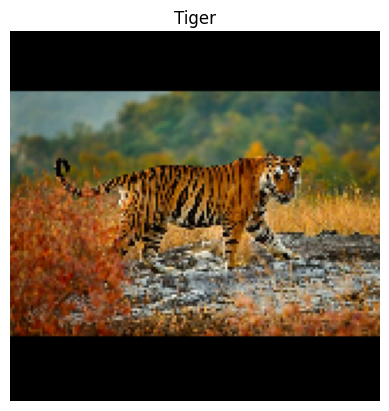

In [35]:
# For Better Understanding Here Is An Visual One Sample Of This Dataset
for images, labels in train_ds.take(1):
    plt.imshow(tf.cast(images[0], tf.uint8).numpy())
    plt.title(class_names[labels[0].numpy()])
    plt.axis("off")
    plt.show()

- The Image Size Has Been Reduced But Now It Is Ready For CNN Model Layers.

In [36]:
# Normalization And Rescaling The Pixel For Better Perfomance Of The Model
normalization = tf.keras.layers.Rescaling(1.0 / 255)

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

- In Rescaling We Have Used RandomFlip, Rotation And Zoom To Add Some Extra Thinking To The Model To Prevent The Chance Of Overfitting And Increase Model Performance.

### Q5 Create An CNN Model For Animal Classification With Different Pooling Window And Convo Layers.

In [37]:
# Creating The Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(160, 160, 3)),
    normalization,           # Normalize Pixel Values from 0-255 To 0-1
    augmentation,            # Apply Random Transformation During Training

    tf.keras.layers.Conv2D(32, (3, 3),strides=(1,1),padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2),strides = (3, 3)),

    tf.keras.layers.Conv2D(64, (3, 3),strides=(1,1),padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2),strides = (3, 3)),

    tf.keras.layers.Conv2D(128, (3, 3),strides=(1,1),padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2),strides = (3, 3)),

    tf.keras.layers.Flatten(),         # Convert feature maps into a vector
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

# Showing The Model Summary
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 53, 53, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 53, 53, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 18, 18, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,974 (2.61 MB)

 Trainable params: 683,974 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

- From The above Summary We Can See That After adding 3 Convo Layers Only The Useful features Of All The Images Where Passed Through All The Kernel And Pooling Window And Then Flattened The Features Into One Vector.

- And Making two 2 Dense Layers For finding More data Patterns In The Vector Passed

- And Predicting 6 Outputs With The Help of Softmax Activation.

In [38]:
# Now We Will Compile the Model
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

# Train The CNN Model by Fitting The Data And Validate Its Output
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=7,restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 251ms/step - accuracy: 0.2407 - loss: 1.7591 - val_accuracy: 0.4232 - val_loss: 1.6395
Epoch 2/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 239ms/step - accuracy: 0.3340 - loss: 1.6030 - val_accuracy: 0.3693 - val_loss: 1.5116
Epoch 3/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 245ms/step - accuracy: 0.4388 - loss: 1.4418 - val_accuracy: 0.5726 - val_loss: 1.1194
Epoch 4/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 246ms/step - accuracy: 0.5259 - loss: 1.2674 - val_accuracy: 0.5187 - val_loss: 1.2140
Epoch 5/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 10s 244ms/step - accuracy: 0.5508 - loss: 1.2027 - val_accuracy: 0.5560 - val_loss: 1.0938
Epoch 6/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 240ms/step - accuracy: 0.6017 - loss: 1.0823 - val_accuracy: 0.6390 - val_loss: 0.9655
Epoch 7/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 248ms/step - accuracy: 0.6255 - loss: 1.0116 - val_accuracy: 0.5643 - val_loss: 1.2733
Epoch 8/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 237ms/step - accuracy: 0.6608 - loss: 0.9101 - val_accuracy: 

### Q6 Evaluate The Trained CNN Model And Show The Visuals Of Validation Curves 

In [40]:
# Evalauting The Model Test_accuracy And Test_loss
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.7483 - loss: 0.7261
Test Loss: 0.7261
Test Accuracy: 74.83%


- As We Can See That Our test_accuracy is around 70 to 75 Percent Which Is Good Enough And We Can say that our model is not overfitted and the performance of our model is very good.

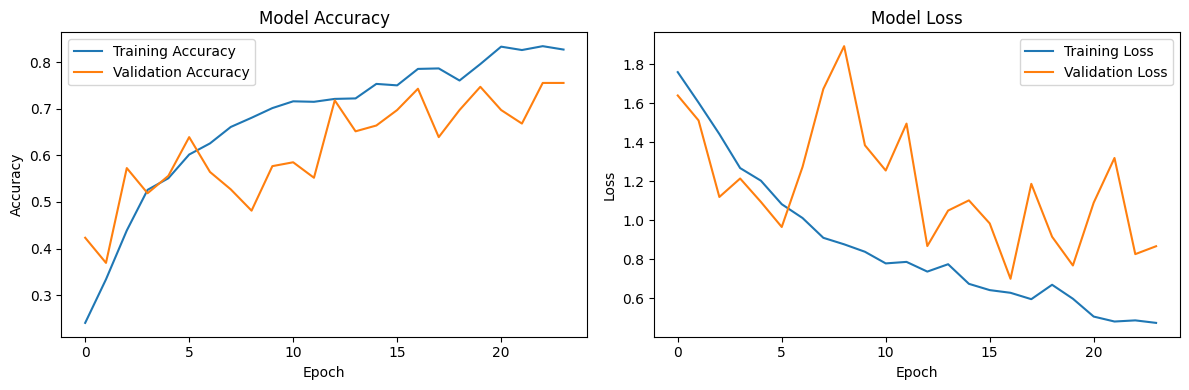

In [39]:
# Ploting The Curves Of The Model
plt.figure(figsize=(12, 4))

# Validation Accuracy VS Training Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Validation Loss VS Validation Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

- From The Above Diagram We can see that The Model Accuracy Is good Because Both The Curves Are Slightly Togather Which Tells the Model Is Not Overfitted.

- And Another One tells that the training loss is gradually decreasing but the validation loss is unstable while decreasing but it is good not the best.

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step


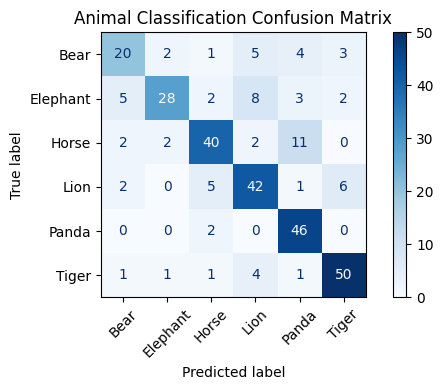

Evaluation Report :
              precision    recall  f1-score   support

        Bear       0.67      0.57      0.62        35
    Elephant       0.85      0.58      0.69        48
       Horse       0.78      0.70      0.74        57
        Lion       0.69      0.75      0.72        56
       Panda       0.70      0.96      0.81        48
       Tiger       0.82      0.86      0.84        58

    accuracy                           0.75       302
   macro avg       0.75      0.74      0.74       302
weighted avg       0.76      0.75      0.74       302



In [46]:
# Showing The Confusion Matrix And Classification Report
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

y_pred = np.argmax(model.predict(test_ds), axis=1)

cm = confusion_matrix(y_true,y_pred,labels=range(len(class_names)))

display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 4))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Animal Classification Confusion Matrix")
plt.tight_layout()
plt.show()

print(f"Evaluation Report :")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0))

- From The Above Report We Can See that Overall The Matrix Score is Good Enough for Everyone.

### Q7 Predicting An Random Image From The Our Dataset And Showing the Confidence Of That predicted Image

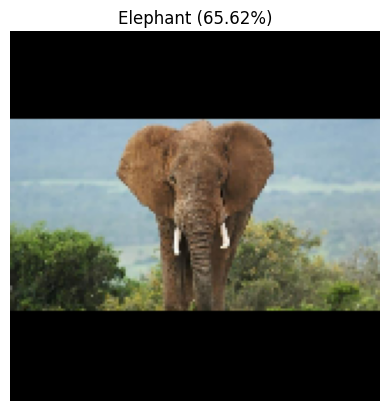

Predicted animal: Elephant
Confidence: 65.62%


In [55]:
# Select a random animal class
animal_class = np.random.choice(class_names)

# Get one image from that class
image_path = os.path.join(
    str(dataset_directory),
    animal_class,
    np.random.choice(os.listdir(os.path.join(str(dataset_directory), animal_class)))
)

# Load the image
image = tf.io.read_file(image_path)
image = tf.io.decode_image(
    image,
    channels=3,
    expand_animations=False
)
image.set_shape([None, None, 3])

# Resize while preserving aspect ratio
image = tf.image.resize_with_pad(image, 160, 160)

# Keep pixel values in the 0–255 range
image = tf.cast(image, tf.float32)

# Add batch dimension
image = tf.expand_dims(image, axis=0)

# Predict
predictions = model.predict(image, verbose=0)[0]

predicted_index = np.argmax(predictions)
predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display image and prediction
plt.imshow(tf.cast(image[0], tf.uint8).numpy())
plt.title(f"{predicted_class} ({confidence:.2f}%)")
plt.axis("off")
plt.show()

print("Predicted animal:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

- This code randomly selects an image from a known class folder in the training dataset and creates its file path.
- It allows us to test the CNN model on an image already present in the dataset and compare the predicted class with its actual class.

- Since the image may have been used during training, this prediction does not measure how well the model generalizes to unseen images.

### Q8 Predicting An Random Image which Is Unseen Or Downloaded From Anywhere And Checking The Confidence To See If The Model Perform Good On Foreign Images.

In [ ]:
# Creating An Predictor
def predict_animal(image_path):
    # Load original image for display
    original_image = tf.io.read_file(image_path)
    original_image = tf.io.decode_image(
        original_image, channels=3, expand_animations=False
    )
    original_image.set_shape([None, None, 3])

    # Prepare image for the CNN
    resized_image = tf.image.resize_with_pad(
        original_image, 160, 160
    )
    resized_image = tf.cast(resized_image, tf.float32)
    image_batch = tf.expand_dims(resized_image, axis=0)

    # Predict
    predictions = model.predict(image_batch, verbose=0)[0]
    predicted_index = np.argmax(predictions)

    return (
        original_image.numpy(),
        class_names[predicted_index],
        predictions[predicted_index] * 100
    )

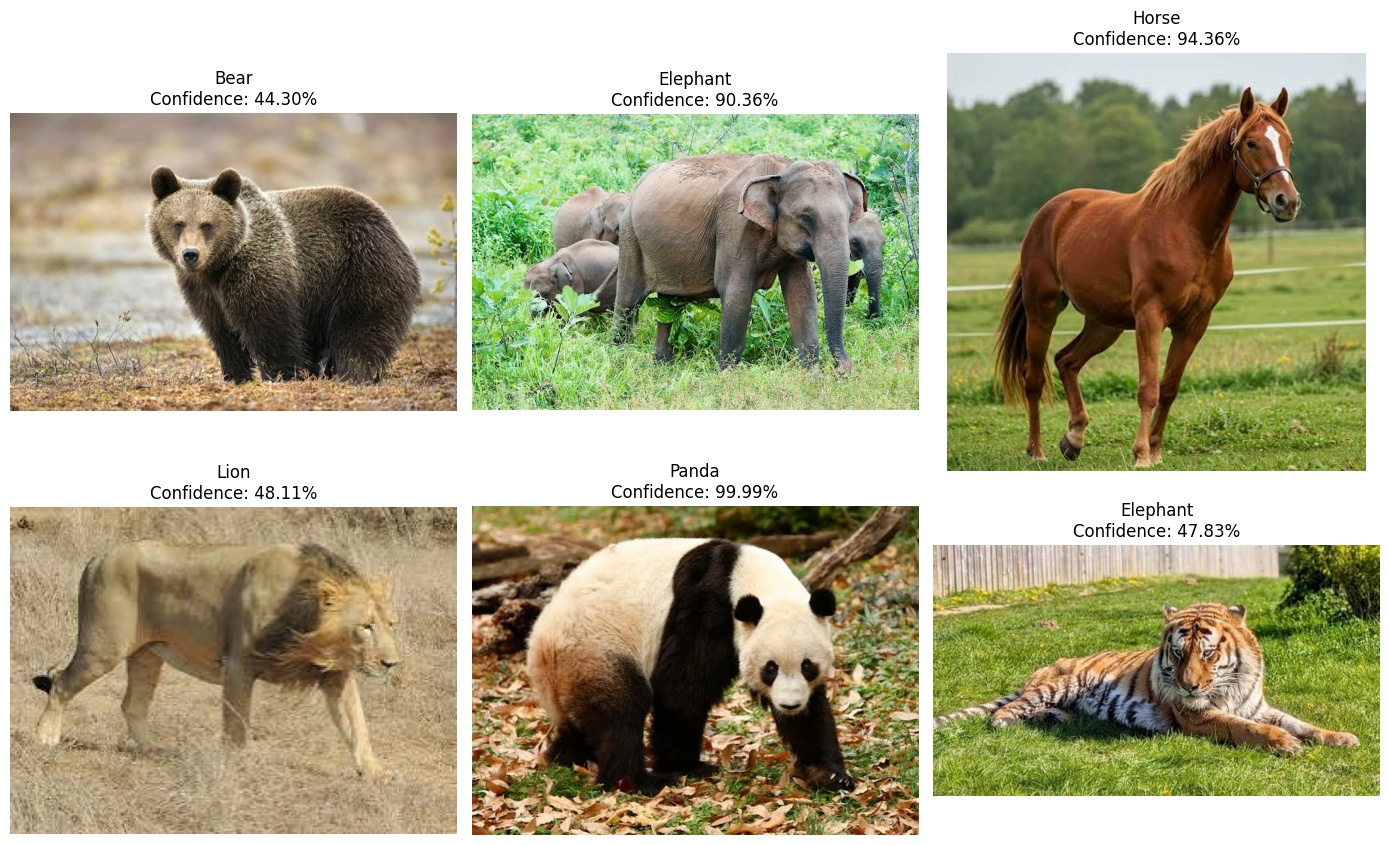

In [ ]:
# Giving One Image For each Class From The Web
image_paths = [
    r"C:\Users\namya\Downloads\bear.jpg",
    r"C:\Users\namya\Downloads\e;ephant.jpg",
    r"C:\Users\namya\Downloads\horse.jpg",
    r"C:\Users\namya\Downloads\lion.jpg",
    r"C:\Users\namya\Downloads\panda.jpg",
    r"C:\Users\namya\Downloads\tiger.jpg"
]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for i, image_path in enumerate(image_paths):
    original_image, predicted_class, confidence = predict_animal(image_path)

    ax = axes[i // 3, i % 3]
    ax.imshow(original_image)
    ax.set_title(f"{predicted_class}\nConfidence: {confidence:.2f}%")
    ax.axis("off")

plt.tight_layout()
plt.show()

- The Model Is Working Good In Predicting But Some Image Class are Still getting Low Confidence But They are manegeable and are future improvements.

### Q9 Save The Model To Be Used Later On

In [68]:
# Save the trained CNN model
model.save("animal_classification_model.keras")
print("Model saved successfully!")

Model saved successfully!
